# សប្ដាហ៍ទី 7 · ការរក្សាទុក និងប្រវត្តិ

ប្រព័ន្ធដែលបាត់បង់ទិន្នន័យរាល់ពេលបិទកម្មវិធី គឺមិនអាចទុកចិត្តបានឡើយ។ ក្នុងសប្ដាហ៍នេះ ប្រព័ន្ធរបស់អ្នកនឹងរៀនរក្សាទុក record ទៅក្នុង file អានវាមកវិញ (load) និងកត់ត្រាប្រវត្តិ (history) ដែលអាចពន្យល់បានថាតើមានអ្វីបានកើតឡើងខ្លះ។

| | |
|---|---|
| **សំណួរសប្ដាហ៍នេះ** | តើប្រព័ន្ធចងចាំដោយរបៀបណា ហើយតើវាអាចពន្យល់ពីអ្វីដែលបានកើតឡើងដោយរបៀបណា? |
| **Python ដែលអ្នកនឹងរៀន** | `open` និង `with`, `"w"` និង `"a"`, `os.path.exists`, `json.dumps` / `json.loads`, `json.dump` / `json.load`, JSON Lines, slice ដូចជា `events[-5:]` |
| **គោលការណ៍ទី 7** | **កុំឱ្យបាត់បង់ទិន្នន័យ។** ត្រូវរក្សាទុកដោយសុវត្ថិភាព រក្សាប្រវត្តិ និងអាចពន្យល់បានថាតើមានអ្វីបានកើតឡើង។ |
| **file ដែលអ្នកបន្ថែម** | `my_foodbridge/storage.py` → `save_records`, `load_records`, `append_event`, `read_events` |
| **អ្វីដែលអ្នកនឹងឃើញ** | `bridge.show("history")`: ទិន្នន័យថ្ងៃគំរូដែលរក្សាទុកដោយកូដរបស់អ្នក ទាំងពីរ file, លំដាប់ព្រឹត្តិការណ៍តាមពេលវេលា (timeline) និងការសាកល្បងចាប់ផ្ដើមឡើងវិញ (restart) ដែល load អ្វីៗទាំងអស់មកវិញ · ក្រាហ្វនៃ file ប្រវត្តិផ្ទាល់ខ្លួនរបស់អ្នក |

*Campus FoodBridge ជាករណីប្រឌិត។ អង្គការ មនុស្ស និងលេខទាំងអស់ សុទ្ធតែប្រឌិតឡើង។*

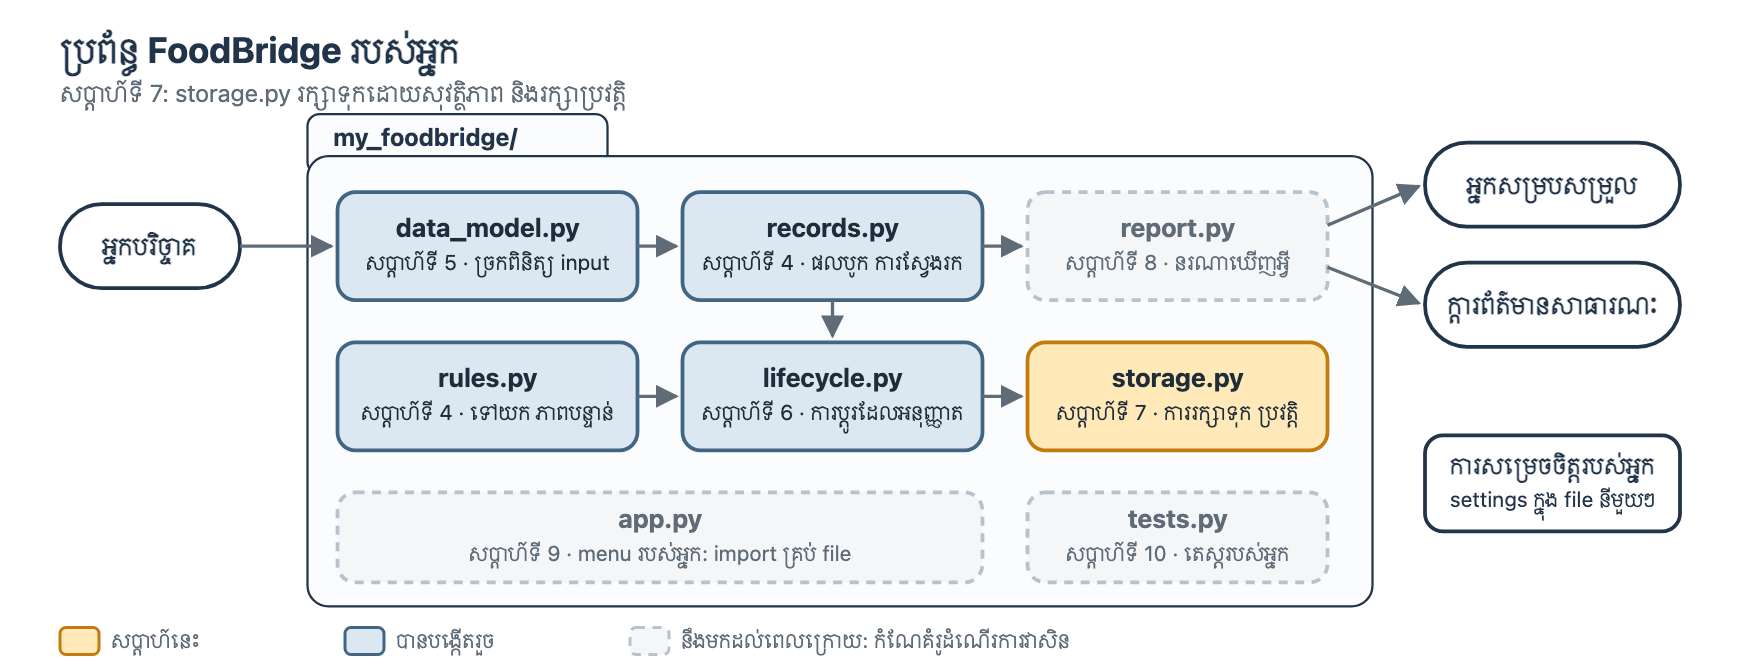

### ដំណើររឿង

folder របស់អ្នកមាន file បួន: `rules.py` និង `records.py` (សប្ដាហ៍ទី 4), `data_model.py` ដែលពិនិត្យជួរទិន្នន័យនីមួយៗនៅច្រកពិនិត្យទិន្នន័យចូល (សប្ដាហ៍ទី 5) និង `lifecycle.py` ដែលអនុញ្ញាតតែការប្ដូរស្ថានភាពដែលសមហេតុផលប៉ុណ្ណោះ (សប្ដាហ៍ទី 6)។ **កូដ** របស់អ្នកមានសុវត្ថិភាព ព្រោះ folder នោះនៅក្នុង Google Drive របស់អ្នក។

ប៉ុន្តែ **ទិន្នន័យ** របស់អ្នកមិនមានសុវត្ថិភាពទេ។ ម្សិលមិញ នៅម៉ោង 4 រសៀល Colab បាន restart។ ការផ្ដល់ជូន (offer) ការអនុម័ត និងការប្រគល់ទាំងអស់ក្នុងថ្ងៃនោះ ស្ថិតនៅក្នុង memory (RAM) ប៉ុណ្ណោះ ហើយឥឡូវនេះវារលុបបាត់អស់ហើយ។ Sunrise Bakery ទូរស័ព្ទមកសួរថា: *«តើនំបុ័ង Bread rolls ចំនួន 30 ចំណែករបស់យើង ទៅណាហើយ?»* គ្មាន file សម្រាប់បើក និងគ្មានប្រវត្តិសម្រាប់អានទេ។

ប្រព័ន្ធក៏ត្រូវ **ចងចាំ** ដែរ: ត្រូវរក្សាទុក record របស់ខ្លួនដោយសុវត្ថិភាព និងរក្សាប្រវត្តិមួយដែលវាអាចពន្យល់បាន។ នោះហើយជាការងាររបស់សប្ដាហ៍នេះ។

## មុនពេលចាប់ផ្ដើម

1. ចូលទៅកាន់ **File → Save a copy in Drive** រួចធ្វើការក្នុងច្បាប់ចម្លងរបស់អ្នក។
2. ចូរ Run setup cell។ នៅក្នុង Colab វានឹងសុំភ្ជាប់ Google Drive៖ សូមយល់ព្រម (yes) ដើម្បីឱ្យ folder `my_foodbridge/` របស់អ្នក នៅរក្សាទុកពីសប្ដាហ៍មួយទៅសប្ដាហ៍មួយ។
3. ⭐ = សម្រាប់គ្រប់គ្នា · ⭐⭐ = សម្រាប់សាកល្បងបន្ថែម។

In [ ]:
# @title ▶ សូម run cell នេះមុនគេ (setup) — វារៀបចំប្រព័ន្ធ FoodBridge
# វាពន្លា (unpack) ប្រព័ន្ធរបស់វគ្គសិក្សា ដែលរក្សាទុកនៅក្នុង notebook នេះ។
# មិនត្រូវការ internet ឬ install អ្វីទេ។ សូម run វាម្ដងទៀត ក្រោយពេល Colab restart។
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.7"
_KIT_SHA = "6cbc4e93859ae41969f7dc55dfcb034f96e7b6ecbe5b22070fdb40497e6251ea"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("ឯកសាររបស់វគ្គសិក្សាក្នុង notebook នេះខូច។ សូមទាញយកច្បាប់ថ្មីមួយ។")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
bridge.set_language("km")     # screens and checks in Khmer
print("✅ ប្រព័ន្ធ FoodBridge រួចរាល់ហើយ (version " + bridge.KIT_VERSION + ")។ អ្នកអាចបន្តបាន។")
bridge.folder.connect()          # រក្សាទុក folder my_foodbridge/ របស់អ្នក (ក្នុង Google Drive នៅក្នុង Colab)


## ចាប់ផ្ដើមថ្នាក់ · ចែករំលែកកិច្ចការស្រាវជ្រាវទី 5 (10 នាទី)

ជាក្រុមបីនាក់ ចូរចែករំលែកអ្វីដែលអ្នកបានរកឃើញ អំពីការរក្សាទិន្នន័យឱ្យមានសុវត្ថិភាព។

1. ចូរផ្ដល់ឧទាហរណ៍ពិតមួយ អំពី **backup (ទិន្នន័យបម្រុងទុក)**, **audit log (កំណត់ត្រាប្រវត្តិសម្រាប់ត្រួតពិនិត្យ)** ឬ **transaction (ប្រតិបត្តិការទិន្នន័យ)** ពីប្រព័ន្ធដែលអ្នកបានសិក្សា។
2. តើមានអ្វីបានកើតឡើង ឬអាចនឹងកើតឡើង នៅពេលទិន្នន័យបាត់បង់? តើនរណារងផលប៉ះពាល់?
3. តើនរណាគួរមានសិទ្ធិអានប្រវត្តិ ហើយតើនរណាមិនគួរមានសិទ្ធិនោះ?

📝 **កំណត់ចំណាំរបស់ខ្ញុំ:** គំនិតមួយពីមិត្តរួមថ្នាក់ ដែលខ្ញុំចង់ចងចាំ …

## វគ្គទី 1 · រៀន និងសាកល្បង (90 នាទី)

### គំនិតសំខាន់: ទិន្នន័យក្នុង memory នឹងរលុបបាត់ ប៉ុន្តែ record ត្រូវតែរក្សាទុកឱ្យគង់វង្ស

សូមគិតអំពីហាងតូចមួយ។ នៅពេលថ្ងៃ ម្ចាស់ហាងកត់ត្រាការលក់នៅលើក្ដារស ដែលត្រូវលុបឱ្យស្អាតនៅពេលយប់។ ម្ចាស់ហាងដែលប្រុងប្រយ័ត្ន ក៏មាន **សៀវភៅកត់ត្រាការលក់** មួយដែរ៖ ការលក់នីមួយៗត្រូវបានសរសេរជាបន្ទាត់ថ្មីមួយដោយទឹកខ្មៅ ព្រមទាំងម៉ោង ហើយកំហុសត្រូវបានកែដោយសរសេរបន្ទាត់ថ្មីមួយទៀត ("សងលុយវិញ, ម៉ោង 2 រសៀល") មិនមែនដោយហែកទំព័រចោលទេ។

Memory (RAM) របស់កម្មវិធីកុំព្យូទ័រ គឺប្រៀបដូចជាក្ដារសនោះដែរ។ រាល់ list និង dictionary របស់អ្នក នឹងរលុបបាត់អស់ នៅពេលកម្មវិធីឈប់ដំណើរការ ឬនៅពេល Colab restart។ ប្រព័ន្ធព័ត៌មានត្រូវការសមត្ថភាពពីរទៀត៖

- **Persistence (ការរក្សាទុកទិន្នន័យឱ្យគង់វង្ស):** record ត្រូវបានរក្សាទុកទៅក្នុង file ដូច្នេះនៅថ្ងៃស្អែក ទិន្នន័យនោះនៅតែមាន។
- **Audit history (កំណត់ត្រាប្រវត្តិសម្រាប់ត្រួតពិនិត្យ):** បញ្ជីព្រឹត្តិការណ៍ ដែលប្រាប់ថា **តើនរណាបានធ្វើអ្វី និងនៅពេលណា**។ យើងមានតែបន្ថែមបន្ទាត់ថ្មីទៅក្នុងវាប៉ុណ្ណោះ (**append-only** មិនលុបឬកែបន្ទាត់ចាស់ឡើយ)។ ដូច្នេះ ប្រសិនបើអ្នកបរិច្ចាគសួរថា *"តើនំបុ័ងរបស់ខ្ញុំ ទៅណាហើយ?"* នោះយើងអាចឆ្លើយបំភ្លឺបាន។

**តើ file នៅឯណា?** file សម្រាប់ហាត់ក្នុងវគ្គទី 1 ត្រូវទៅក្នុង folder ផ្ទាល់របស់ notebook ហើយវានឹងបាត់ នៅពេល runtime ឈប់ (មិនអីទេសម្រាប់ការហាត់)។ file របស់ប្រព័ន្ធអ្នក ត្រូវទៅក្នុង `my_foodbridge/` ដែលរក្សាទុកក្នុង Google Drive របស់អ្នក។ ផ្ទាំង **Files** (រូប folder នៅខាងឆ្វេង) បង្ហាញទាំងពីរ។

### 1 · សរសេរ file មួយ រួចអានវាម្ដងមួយបន្ទាត់

`open` ភ្ជាប់កម្មវិធីរបស់អ្នកទៅនឹង file មួយ។ `with` បិទ file ឱ្យអ្នក នៅចុងបញ្ចប់នៃ block សូម្បីតែនៅពេលមានអ្វីមួយខុសក៏ដោយ។ `"w"` មានន័យថា *write* (សរសេរ)។ ប្រសិនបើគ្មាន mode ទេ `open` គ្រាន់តែអាន file ប៉ុណ្ណោះ។ `for` loop លើ file មួយ ផ្ដល់ឱ្យអ្នកម្ដងមួយបន្ទាត់។

🤔 **ទាយមើល:** តើ loop នឹង print ប៉ុន្មានបន្ទាត់? ហើយតើ `line.strip()` ដកអ្វីចេញ?

In [ ]:
with open("shopping.txt", "w", encoding="utf-8") as file:
    file.write("rice\n")
    file.write("eggs\n")

with open("shopping.txt", encoding="utf-8") as file:
    for line in file:
        print("-", line.strip())

**រំពឹងថា:** …  **លទ្ធផលជាក់ស្ដែង:** …

`"\n"` បញ្ចប់បន្ទាត់មួយ។ `write` មិនបន្ថែមវាឱ្យអ្នកទេ ហើយ `strip()` ដកវាចេញវិញ នៅពេលអ្នកអាន។ `encoding="utf-8"` អនុញ្ញាតឱ្យ file ផ្ទុកភាសាណាក៏បាន រួមទាំងភាសាខ្មែរ។

### 2 · `"w"` ធ្វើឱ្យ file ទទេ, `"a"` បន្ថែមនៅខាងចុង

ការបើក file ដោយប្រើ mode ខុស គឺជាមូលហេតុមួយដែលកើតឡើងញឹកញាប់បំផុត ដែលធ្វើឱ្យកម្មវិធីកុំព្យូទ័របាត់បង់ទិន្នន័យ។

🤔 **ទាយមើល:** តើផ្នែកចុងក្រោយនឹង print អ្វី? នៅពេលចាប់ផ្ដើម file មានពីរបន្ទាត់ គឺ *maths* និង *English*។

In [ ]:
with open("homework.txt", "w", encoding="utf-8") as file:
    file.write("maths\n")
    file.write("English\n")

with open("homework.txt", "w", encoding="utf-8") as file:     # "w" ម្ដងទៀត
    file.write("history\n")

with open("homework.txt", "a", encoding="utf-8") as file:     # "a"
    file.write("Khmer\n")

with open("homework.txt", encoding="utf-8") as file:
    print(file.read())

**រំពឹងថា:** …  **លទ្ធផលជាក់ស្ដែង:** …  **ហេតុអ្វី:** …

`"w"` ធ្វើឱ្យ file ទទេ **ភ្លាមៗនៅពេលវាបើក** គឺមុនពេលអ្នកសរសេរអ្វីមួយចូល។ *maths* និង *English* បាត់អស់ ហើយ Python មិនព្រមានអ្នកអ្វីសោះ។ `"a"` (*append*) រក្សាអ្វីៗដែលមានស្រាប់ទាំងអស់ ហើយបន្ថែមនៅខាងចុង។

### ✍️ សាកសរសេរ · `add_sale`

សៀវភៅកត់ត្រាការលក់របស់ហាង ចាប់ផ្ដើមថ្ងៃដោយមានការលក់មួយ។ ចូរសរសេរ `add_sale(path, sale)`: វាត្រូវបន្ថែម `sale` ជាបន្ទាត់ថ្មីមួយ នៅ **ខាងចុង** file រួចអាន file នោះម្ដងមួយបន្ទាត់ ហើយ return គ្រប់បន្ទាត់ (ដោយគ្មាន `"\n"`)។ ការពិនិត្យ (check) មើលថា តើការលក់ចាស់ៗនៅតែមានឬទេ។

In [ ]:
with open("sales_book.txt", "w", encoding="utf-8") as file:   # ថ្ងៃចាប់ផ្ដើមដោយមានការលក់មួយ
    file.write("08:00 two bread rolls\n")


def add_sale(path, sale):
    # TODO 1: បើក path ដោយ "a" (និង encoding="utf-8") ហើយសរសេរ sale + "\n"
    lines = []
    # TODO 2: បើក path ម្ដងទៀតដើម្បីអានវា; សម្រាប់បន្ទាត់នីមួយៗ ចូរ append line.strip() ទៅក្នុង lines
    return lines


bridge.check("add_sale", add_sale, examples=[
    (("sales_book.txt", "09:15 one rice box"), ["08:00 two bread rolls", "09:15 one rice box"]),
    (("sales_book.txt", "10:30 three bananas"), ["08:00 two bread rolls", "09:15 one rice box", "10:30 three bananas"]),
])

### 3 · តើ file មានឬទេ? `os.path.exists`

ប្រសិនបើអ្នកអាន file ដែលមិនមាន កម្មវិធីនឹងឈប់ដំណើរការ ជាមួយ `FileNotFoundError`។ នៅថ្ងៃដំបូងនៃប្រព័ន្ធថ្មីមួយ មិនទាន់មាន file នៅឡើយទេ។ នោះជារឿងធម្មតា មិនមែនជាបញ្ហា (error) ទេ ដូច្នេះត្រូវពិនិត្យជាមុនសិន។

In [ ]:
import os

print(os.path.exists("shopping.txt"))
print(os.path.exists("diary.txt"))

លំនាំដែលអ្នកនឹងប្រើពេញមួយសប្ដាហ៍៖ **ប្រសិនបើ file មាន ត្រូវអានវា។ ប្រសិនបើមិនមាន ត្រូវចាប់ផ្ដើមជាមួយ list ទទេ។**

### 4 · JSON: list និង dictionary ជា text

file មួយអាចផ្ទុកបានតែ text ប៉ុណ្ណោះ ប៉ុន្តែ record របស់អ្នកជា list និង dictionary។ **JSON** គឺជាវិធីស្ដង់ដារមួយ សម្រាប់សរសេរវាជា text។ មនុស្សអាចអានវាបាន ហើយភាសាសរសេរកម្មវិធីស្ទើរតែទាំងអស់ អាចអាន (load) វាបាន។ `json.dumps` បម្លែងទិន្នន័យទៅជា JSON text។ `json.loads` បម្លែង JSON text ត្រឡប់ទៅជាទិន្នន័យវិញ។ (អក្សរ `s` មានន័យថា *string*។)

🤔 **ទាយមើល:** សូមមើលបន្ទាត់ចុងក្រោយ។ តើ `back["credit_usd"]` ជា text ឬជាលេខ?

In [ ]:
import json

phone = {"owner": "Dara", "credit_usd": 5, "plans": ["data", "calls"], "active": True}
text = json.dumps(phone)
print(text)
print(type(text))

back = json.loads(text)
print(back["credit_usd"] + 1)

**រំពឹងថា:** …  **លទ្ធផលជាក់ស្ដែង:** …

នៅសប្ដាហ៍ទី 5 តម្លៃនីមួយៗដែលអានពី CSV file គឺជា text ដូច្នេះអ្នកត្រូវប្រើ `int()`។ JSON រក្សាលេខឱ្យនៅជាលេខ (ហើយវាសរសេរ `True` ជា `true`)។ នេះជាមូលហេតុមួយ ដែលធ្វើឱ្យ JSON ជាទម្រង់ល្អសម្រាប់ record។

### ✍️ សាកសរសេរ · `top_up`

ហាងទូរស័ព្ទមួយ រក្សាគណនីនីមួយៗជា JSON text។ ចូរសរសេរ `top_up(text, amount)`៖

- អាន (load) គណនីនោះ។
- បន្ថែម `amount` ទៅលើ `"credit_usd"` របស់វា។
- return JSON text ថ្មី។

In [ ]:
def top_up(text, amount):
    # TODO 1: account = json.loads(text)
    # TODO 2: បន្ថែម amount ទៅលើ account["credit_usd"]
    # TODO 3: return json.dumps(account)
    return text


bridge.check("top_up", top_up, examples=[
    (('{"owner": "Dara", "credit_usd": 5}', 2), '{"owner": "Dara", "credit_usd": 7}'),
    (('{"owner": "Sokha", "credit_usd": 0}', 10), '{"owner": "Sokha", "credit_usd": 10}'),
])

### 5 · `json.dump` និង `json.load` ធ្វើការជាមួយ file

នៅពេលគ្មានអក្សរ `s` ទេ function ដដែលទាំងពីរនេះ សរសេរទៅក្នុង file និងអានពី file។ `indent=2` ដាក់ item នីមួយៗនៅលើបន្ទាត់ដាច់ដោយឡែក ដូច្នេះមនុស្សក៏អាចអាន file នេះបានដែរ។

In [ ]:
classes = [{"code": "MIS101", "students": 42}, {"code": "ACC102", "students": 35}]

with open("classes.json", "w", encoding="utf-8") as file:
    json.dump(classes, file, indent=2)

with open("classes.json", encoding="utf-8") as file:
    loaded = json.load(file)

print(loaded[1]["students"])
print(loaded == classes)

ចូរបើក `classes.json` នៅក្នុងផ្ទាំង Files (ចុចពីរដងលើវា) ហើយមើល: វាជា text ធម្មតា។

### ✍️ សាកសរសេរ · `load_list`

ចូរសរសេរ `load_list(path)`៖

- ប្រសិនបើគ្មាន file នៅ `path` ទេ ត្រូវ return `[]`។
- ប្រសិនបើមាន ត្រូវ return list ដែលបានរក្សាទុកក្នុង file។

នេះជារបៀបដែលប្រព័ន្ធថ្មីមួយចាប់ផ្ដើម នៅថ្ងៃដំបូងរបស់វា ហើយវាស្ទើរតែជា `load_records` របស់អ្នករួចទៅហើយ។

In [ ]:
def load_list(path):
    # TODO 1: ប្រសិនបើគ្មាន file នៅ path ទេ ត្រូវ return []   (ប្រើ os.path.exists)
    # TODO 2: ប្រសិនបើមាន ត្រូវបើក file ហើយ return json.load(file)
    return None


bridge.check("load_list", load_list, examples=[
    ("classes.json", [{"code": "MIS101", "students": 42}, {"code": "ACC102", "students": 35}]),
    ("no_such_file.json", []),
])

### 6 · JSON Lines: ប្រវត្តិដែលយើងគ្រាន់តែបន្ថែមចូល

ប្រវត្តិមានទម្រង់ខុសពី list នៃ record។ យើងមិនដែលសរសេរវាឡើងវិញទេ គឺយើង **បន្ថែមមួយបន្ទាត់ សម្រាប់ព្រឹត្តិការណ៍នីមួយៗ**។ បន្ទាត់នីមួយៗគឺជា JSON object តូចមួយ។ របៀបនេះហៅថា **JSON Lines** ហើយឈ្មោះ file ប្រភេទនេះបញ្ចប់ដោយ `.jsonl`។

In [ ]:
def log_event(path, event):
    with open(path, "a", encoding="utf-8") as file:     # "a": បន្ថែមនៅខាងចុង មិនដែលធ្វើឱ្យទទេ
        file.write(json.dumps(event) + "\n")             # ព្រឹត្តិការណ៍មួយ = មួយបន្ទាត់


log_event("phone_history.jsonl", {"time": "09:00", "event": "top up", "usd": 5})
log_event("phone_history.jsonl", {"time": "09:30", "event": "bought data", "usd": 3})

with open("phone_history.jsonl", encoding="utf-8") as file:
    for line in file:
        event = json.loads(line)
        print(event["time"], event["event"], event["usd"])

🤔 **ទាយមើល រួចសាកល្បង:** ចូរ run cell ខាងលើម្ដងទៀត។ តើមានអ្វីកើតឡើងចំពោះប្រវត្តិ? តើនេះត្រឹមត្រូវសម្រាប់ប្រវត្តិដែរឬទេ? ចុះសម្រាប់ list នៃ record វិញ តើវាត្រឹមត្រូវដែរឬទេ?

**រំពឹងថា:** …  **លទ្ធផលជាក់ស្ដែង:** …  **ហេតុអ្វី:** …

### 7 · Slice: item ពីរបីចុងក្រោយ

ប្រវត្តិកើនឡើងពេញមួយថ្ងៃ ប៉ុន្តែអេក្រង់មានកន្លែងសម្រាប់តែពីរបីបន្ទាត់ប៉ុណ្ណោះ។ សញ្ញាវង់ក្រចកជ្រុង `[ : ]` ដែលមានសញ្ញាចុចពីរ (colon) នៅខាងក្នុង ប្រើសម្រាប់កាត់យក **slice** (ផ្នែកណាមួយនៃ list ឬ text)។ សញ្ញាដក (minus) រាប់បញ្ច្រាសពីខាងចុងមកវិញ។

🤔 **ទាយមើល:** សូមមើលបន្ទាត់ចុងក្រោយ។ ប្រសិនបើមានតែ 7 item តើ "10 ចុងក្រោយ" ជាអ្វី?

In [ ]:
calls = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(calls[:2])      # 2 ដំបូង
print(calls[-3:])     # 3 ចុងក្រោយ
print(calls[-10:])

**រំពឹងថា:** …  **លទ្ធផលជាក់ស្ដែង:** …

slice មិនដែលធ្វើឱ្យកម្មវិធីរបស់អ្នកឈប់ទេ សូម្បីតែនៅពេល list ខ្លីជាងអ្វីដែលអ្នកសុំក៏ដោយ។ វាក៏បង្កើត list **ថ្មី** មួយដែរ: `calls` មិនប្រែប្រួលទេ។

### ⭐⭐ សាកសរសេរ · `last_five`

*ស្រេចចិត្ត។* អេក្រង់របស់អ្នកសម្របសម្រួល បង្ហាញព្រឹត្តិការណ៍ថ្មីបំផុតប្រាំ។ ចូរសរសេរ `last_five(events)`: វាត្រូវ return item 5 ចុងក្រោយនៃ list (ឬ return ទាំងអស់ ប្រសិនបើមានតិចជាង 5)។

In [ ]:
def last_five(events):
    # TODO: return slice មួយ ដែលមាន item 5 ចុងក្រោយនៃ events
    return []


bridge.check("last_five", last_five, examples=[
    (["#1", "#2", "#3", "#4", "#5", "#6", "#7"], ["#3", "#4", "#5", "#6", "#7"]),
    (["#1", "#2"], ["#1", "#2"]),
    ([], []),
])

### ✍️ សាកសរសេរ · `count_events` (FoodBridge)

ក្នុង FoodBridge ព្រឹត្តិការណ៍នីមួយៗក្នុងប្រវត្តិ គឺជា dictionary មួយ។ key `"event"` របស់វាប្រាប់ថា វាជាព្រឹត្តិការណ៍ប្រភេទណា: `"added"`, `"input_rejected"` ឬ `"moved"`។ ចូរសរសេរ `count_events(events)`: វាត្រូវ return dictionary មួយ `{ប្រភេទព្រឹត្តិការណ៍: ចំនួន}`។ នេះគឺជា dictionary accumulator ដែលអ្នកបានរៀននៅសប្ដាហ៍ទី 3។

In [ ]:
def count_events(events):
    counts = {}
    # TODO: សម្រាប់ event នីមួយៗ ចូរបន្ថែម 1 ទៅ counts[event["event"]]   (counts.get(kind, 0) + 1)
    return counts


short_day = [
    {"step": 1, "event": "added", "offer": "F001"},
    {"step": 2, "event": "added", "offer": "F002"},
    {"step": 3, "event": "input_rejected", "offer": ""},
    {"step": 4, "event": "moved", "offer": "F002"},
]
bridge.check("count_events", count_events, examples=[
    (short_day, {"added": 2, "input_rejected": 1, "moved": 1}),
    ([], {}),
])

### ✍️ សាកសរសេរ · `story_of` (FoodBridge)

Sunrise Bakery ទូរស័ព្ទមកសួរថា: *«តើនំបុ័ង Bread rolls របស់យើង ទៅណាហើយ?»* ចូរសរសេរ `story_of(events, offer_id)`: វាត្រូវ return `"detail"` នៃគ្រប់ព្រឹត្តិការណ៍អំពីសំណើនោះ ដោយចាស់បំផុតនៅមុនគេ។ នេះហើយជាគោលបំណងនៃប្រវត្តិសម្រាប់ត្រួតពិនិត្យ (audit history)។

In [ ]:
def story_of(events, offer_id):
    details = []
    # TODO: សម្រាប់ event នីមួយៗដែល "offer" របស់វាជា offer_id ចូរ append event["detail"] ទៅក្នុង details
    return details


bakery_day = [
    {"step": 1, "event": "added", "offer": "F001", "detail": "30 portions of Bread rolls"},
    {"step": 2, "event": "added", "offer": "F002", "detail": "18 portions of Fried rice boxes"},
    {"step": 3, "event": "moved", "offer": "F001", "detail": "new -> approved for Hope Children's Centre"},
    {"step": 4, "event": "moved", "offer": "F001", "detail": "approved -> picked_up"},
]
bridge.check("story_of", story_of, examples=[
    ((bakery_day, "F001"), ["30 portions of Bread rolls", "new -> approved for Hope Children's Centre",
                            "approved -> picked_up"]),
    ((bakery_day, "F002"), ["18 portions of Fried rice boxes"]),
    ((bakery_day, "F999"), []),
])

## វគ្គទី 2 · អនុវត្ត និងវាយតម្លៃ (90 នាទី)

*ប្រសិនបើអ្នកបើក notebook នេះក្នុងវគ្គថ្មី សូម Run setup cell នៅខាងលើគេជាមុនសិន ដើម្បីឱ្យ `bridge` រួចរាល់។*

### 🚨 ការហ្វឹកហាត់ដោះស្រាយបញ្ហាបន្ទាន់ (incident drill): runtime បាត់អស់ (20 នាទី)

ក្រុមការងារពិតប្រាកដ ហាត់ដោះស្រាយគ្រោះមហន្តរាយ **មុនពេល** វាកើតឡើង។ ជាដំបូង ចូរពិនិត្យថា setup cell បានប្រាប់ថា folder របស់អ្នកនៅក្នុង **Google Drive**។ ប្រសិនបើមិនមែនទេ ចូរគ្រាន់តែមើលអេក្រង់របស់គ្រូ (បើមិនដូច្នោះទេ អ្នកនឹងបាត់បង់ folder របស់អ្នក)។

1. 🤔 នៅក្នុងផ្ទាំង **Files** ចូរទាយមើលថា តើអ្វីខ្លះនៅសល់ ក្រោយពេល runtime ត្រូវបានលុប: `shopping.txt`, `classes.json`, file ក្នុង `my_foodbridge/` របស់អ្នក និងអថេរ `short_day`។
2. **Runtime → Disconnect and delete runtime។** ចូរភ្ជាប់ឡើងវិញ (reconnect) រួច Run **តែ** setup cell ប៉ុណ្ណោះ បន្ទាប់មក Run cell ខាងក្រោម។
3. ចូរប្រៀបធៀប: file សម្រាប់ហាត់ និងអថេរទាំងអស់បាត់អស់ ឯ `my_foodbridge/` បានត្រឡប់មកវិញពី Drive។ តើអ្វីជា backup? តើ Sunrise Bakery នឹងបាត់បង់អ្វី ប្រសិនបើ FoodBridge រក្សាទុកការផ្ដល់ជូនរបស់ខ្លួនតែក្នុង memory ប៉ុណ្ណោះ?

In [ ]:
import os

print("shopping.txt (practice file):", os.path.exists("shopping.txt"))
if os.path.exists("my_foodbridge"):
    print("my_foodbridge/ (in Drive):", sorted(os.listdir("my_foodbridge")))

📝 **កំណត់ចំណាំរបស់ខ្ញុំ:** អ្វីដែលនៅសល់ អ្វីដែលបាត់ និងមូលហេតុ។

### 🎫 ប័ណ្ណការងារសប្ដាហ៍នេះ (ticket)

> **ពី:** អ្នកសម្របសម្រួល · **ទៅ:** អ្នក
> "ម្សិលមិញ Colab បាន restart នៅម៉ោង 4 រសៀល ហើយទិន្នន័យពេញមួយថ្ងៃបានបាត់អស់។ Sunrise Bakery ទូរស័ព្ទមកសួរអំពីនំបុ័ង 30 ចំណែករបស់ខ្លួន ហើយខ្ញុំមិនអាចប្រាប់បានថាមានអ្វីកើតឡើងទេ។ ខ្ញុំត្រូវការឱ្យប្រព័ន្ធរក្សាទុករាល់ការផ្លាស់ប្ដូរ អានអ្វីៗទាំងអស់មកវិញនៅពេលព្រឹក និងរក្សាប្រវត្តិមួយដែលខ្ញុំអាចអានបាន។"

| | |
|---|---|
| **File** | `my_foodbridge/storage.py` |
| **Setting** | `LOG_EVENTS`: ប្រភេទព្រឹត្តិការណ៍ដែលប្រវត្តិរក្សាទុក (default `["added", "input_rejected", "moved"]`) |
| **Function** | `save_records(records, path)` · `load_records(path)` · `append_event(path, event)` · `read_events(path)` |
| **របៀបដែលប្រព័ន្ធប្រើវា** | ក្រោយការផ្លាស់ប្ដូរនីមួយៗ វាហៅ `save_records` របស់អ្នក; សម្រាប់ព្រឹត្តិការណ៍នីមួយៗក្នុង `LOG_EVENTS` វាហៅ `append_event` របស់អ្នក; នៅពេលចាប់ផ្ដើម វាហៅ `load_records` និង `read_events` របស់អ្នក |
| **រួចរាល់នៅពេល** | ការពិនិត្យទាំងបួនជាប់ ហើយ `bridge.show("history")` បង្ហាញផ្នែកទាំងបួនរបស់អ្នក ✅ និងតេស្តចាប់ផ្ដើមឡើងវិញ (restart test) ដែលទទួលបាន record 4 ដដែលមកវិញ |

*សូមប្រយ័ត្នលំដាប់ parameter: `save_records(records, path)` ទទួលទិន្នន័យមុន រីឯ `append_event(path, event)` ទទួល `path` មុន។*

| ការហៅ | អ្វីដែលត្រូវកើតឡើង |
|---|---|
| `save_records(records, "offers.json")` | file មានតែ list នោះពិតប្រាកដ; ការរក្សាទុកម្ដងទៀត **ជំនួស** វា |
| `load_records("offers.json")` | បាន list ដដែលមកវិញ ហើយលេខនៅតែជាលេខ |
| `load_records("nothing_saved.json")` | `[]` (មិនទាន់មាន file គឺជារឿងធម្មតា) |
| `append_event("history.jsonl", event)` ពីរដង | មានពីរបន្ទាត់ក្នុង file; បន្ទាត់ទីមួយនៅតែមាន |
| `read_events("history.jsonl")` | គ្រប់ព្រឹត្តិការណ៍ ដោយចាស់បំផុតនៅមុនគេ |
| `read_events("nothing_logged.jsonl")` | `[]` |

### ✏️ គូរគំរូលើក្រដាសជាមុនសិន

ចូរគូរប្រអប់ពីរលើក្រដាស: `offers.json` និង `history.jsonl`។ បន្ទាប់មក មានរឿងបីកើតឡើង៖

1. F001 នំបុ័ង Bread rolls 30 ចំណែក ត្រូវបានបញ្ចូល។
2. ជួរទិន្នន័យមួយត្រូវបានបដិសេធនៅច្រកពិនិត្យទិន្នន័យចូល: "portions must be a whole number"។
3. F001 ត្រូវបានអនុម័ត សម្រាប់ Hope Children's Centre។

ក្រោយជំហាននីមួយៗ ចូរគូរអ្វីដែលមាននៅក្នុង file នីមួយៗ។ បន្ទាប់មក សូមឆ្លើយសំណួរខាងក្រោម៖ តើ file មួយណាត្រូវបាន **ជំនួស** រាល់ពេល? តើ file មួយណាគ្រាន់តែ **កើនឡើង**?

In [ ]:
# 📝 ចូររៀបរាប់ពីគំនូររបស់អ្នកនៅទីនេះ (ឬដាក់រូបថតក្នុង text cell មួយ)។

### 🧩 លំហាត់តាមកម្រិត (Ladder 1) · រៀបបន្ទាត់កូដតាមលំដាប់

ក្រុមអ្នកស្ម័គ្រចិត្តរក្សាប្រវត្តិចុះឈ្មោះ (sign-in) ជា JSON Lines។ ចូរចុចលើបន្ទាត់ទាំងនោះ ដើម្បីរៀបវាតាមលំដាប់។ មានបន្ទាត់កូដបញ្ឆោតមួយដែលមិនត្រូវប្រើទេ។

In [ ]:
bridge.parsons("sign_in_history")

<details><summary>មើលចម្លើយល្បែងផ្គុំកូដ (ប្រសិនបើអាននៅលើគេហទំព័រ)</summary>

```python
def read_sign_ins(path):
    sign_ins = []
    if not os.path.exists(path):
        return sign_ins
    with open(path, encoding="utf-8") as file:
        for line in file:
            sign_ins.append(json.loads(line))
    return sign_ins
```

បន្ទាត់បញ្ឆោត `with open(path, "w", encoding="utf-8") as file:` មិនត្រូវប្រើទេ៖ `"w"` ធ្វើឱ្យ file ទទេភ្លាមៗពេលវាបើក ដែលនឹងលុបប្រវត្តិចុះឈ្មោះទាំងអស់។

</details>

### 🧩 លំហាត់តាមកម្រិត (Ladder 2) · សរសេរកូដដោយខ្លួនឯងពីដំបូង

អ្នកសម្របសម្រួលចង់ដឹងថា ហេតុអ្វីបានជាជួរទិន្នន័យខ្លះត្រូវបានបដិសេធនៅច្រកពិនិត្យទិន្នន័យចូលថ្ងៃនេះ។ ចូរសរសេរ `refused_rows(path)`៖

- អាន history file របស់ FoodBridge នៅ `path`។
- return `"detail"` នៃគ្រប់ព្រឹត្តិការណ៍ `"input_rejected"` ដោយចាស់បំផុតនៅមុនគេ។
- return `[]` ប្រសិនបើគ្មាន file។

In [ ]:
import json
import os

practice_day = [
    {"step": 1, "event": "added", "offer": "F001", "detail": "30 portions of Bread rolls"},
    {"step": 2, "event": "input_rejected", "offer": "", "detail": "portions must be a whole number, for example 12."},
    {"step": 3, "event": "input_rejected", "offer": "", "detail": "donor is required."},
    {"step": 4, "event": "moved", "offer": "F001", "detail": "new -> approved for Hope Children's Centre"},
]
with open("practice_history.jsonl", "w", encoding="utf-8") as file:   # ប្រវត្តិខ្លីមួយ សម្រាប់សាកល្បង
    for event in practice_day:
        file.write(json.dumps(event) + "\n")


def refused_rows(path):
    # កូដរបស់អ្នកនៅទីនេះ។
    return None


bridge.check("refused_rows", refused_rows, examples=[
    ("practice_history.jsonl", ["portions must be a whole number, for example 12.", "donor is required."]),
    ("no_history.jsonl", []),
])

### ⚖️ ល្អ ឬមានហានិភ័យ?

អ្នកបានសួរជំនួយការ AI (AI assistant) មួយថា៖ *"សូមសរសេរ function មួយ ដែលរក្សាទុកសំណើប្រចាំថ្ងៃ និងប្រវត្តិ នៅចុងថ្ងៃ។ សូមរក្សា file ឱ្យតូច។"* វាបានផ្ដល់ឱ្យអ្នកនូវ **Version A**។ **Version B** ប្រើផ្នែកដែលអ្នកបានរៀននៅសប្ដាហ៍នេះ។ នៅថ្ងៃធម្មតា ទាំងពីរដំណើរការបានដោយគ្មានបញ្ហា (error)។

**Version A** (ពីជំនួយការ AI)

```python
def save_day(records, events):
    with open("offers.json", "w") as file:
        json.dump(records, file)
    # រក្សាប្រវត្តិឱ្យតូច: យកតែ 10 events ចុងក្រោយ
    with open("history.jsonl", "w") as file:
        for event in events[-10:]:
            file.write(json.dumps(event) + "\n")
```

**Version B**

```python
def save_day(records, new_events):
    temp_path = "offers.json.tmp"
    with open(temp_path, "w", encoding="utf-8") as file:   # 1. សរសេរទិន្នន័យថ្មីនៅទីនេះ
        json.dump(records, file, indent=2)
    os.replace(temp_path, "offers.json")                    # 2. ប្ដូរវាចូលជំនួស ក្នុងមួយជំហាន
    with open("history.jsonl", "a", encoding="utf-8") as file:
        for event in new_events:
            file.write(json.dumps(event) + "\n")            # បន្ថែមនៅខាងចុង; មិនដែលសរសេរឡើងវិញ
```

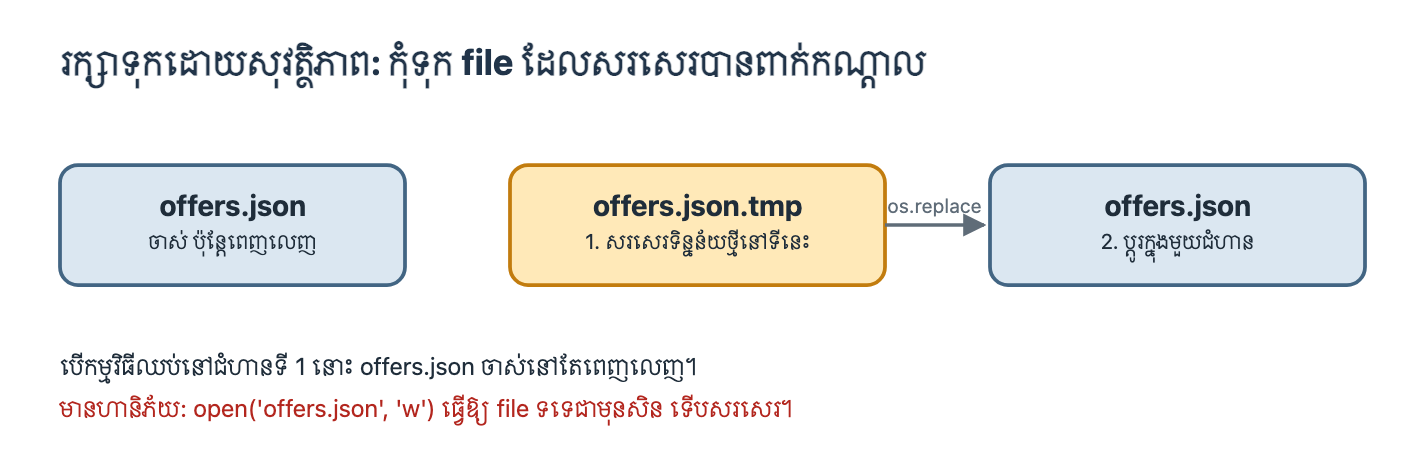

សូមប្រើថ្ងៃគំរូ៖

- នំបុ័ង F001 ត្រូវបានទៅយក សម្រាប់ Hope Children's Centre។
- បាយ F002 ត្រូវបានប្រគល់រួច។
- ចេក F003 ត្រូវបានបដិសេធ ("ថ្ងៃនេះគ្មានកន្លែងទុកត្រជាក់សម្រាប់ផ្លែឈើ")។
- ការី F004 ត្រូវបានអនុម័ត ហើយកំពុងរង់ចាំ Old Market Elders' Group។
- ថ្ងៃនោះមាន 16 ព្រឹត្តិការណ៍។

1. តើសំណើណា ឬនរណា រងផលប៉ះពាល់ដោយសារ Version A? ចូរចង្អុលបង្ហាញបន្ទាត់នោះ។
2. សូមមើល Version B និងគំនូសតាង៖ តើ `offers.json.tmp` លេចឡើងនៅពេលណា ហើយនៅបានរយៈពេលប៉ុន្មាន? ប្រសិនបើភ្លើងដាច់នៅពាក់កណ្ដាលនៃការរក្សាទុក តើនៅសល់អ្វីខ្លះ ជាមួយ version នីមួយៗ? (ចូរ run ការពិសោធន៍ខាងក្រោម។)
3. តើតេស្ត (test) អាចរកឃើញបញ្ហានីមួយៗដោយរបៀបណា?

🔌 **ដកខ្សែភ្លើង។** សំណើពីរពីម្សិលមិញ ត្រូវបានរក្សាទុករួចហើយ។ ការរក្សាទុកសំណើបីនៅថ្ងៃនេះ ឈប់ក្រោយ 25 តួអក្សរ (`text[:25]` គឺជា slice នៃ text)។ ចូរ run cell នេះ ហើយអានលទ្ធផល។

In [ ]:
import json

yesterday = [{"id": "F001", "portions": 30}, {"id": "F002", "portions": 18}]
for path in ["risky.json", "safe.json"]:
    with open(path, "w", encoding="utf-8") as file:
        json.dump(yesterday, file)

today = yesterday + [{"id": "F003", "portions": 40}]
text = json.dumps(today)

# Version A សរសេរចូល file ដោយផ្ទាល់ ... ហើយភ្លើងដាច់ក្រោយ 25 តួអក្សរ។
with open("risky.json", "w", encoding="utf-8") as file:
    file.write(text[:25])

# Version B សរសេរ file បណ្ដោះអាសន្ន ... ហើយភ្លើងដាច់មុន os.replace។
with open("safe.json.tmp", "w", encoding="utf-8") as file:
    file.write(text[:25])

for path in ["risky.json", "safe.json"]:
    try:
        with open(path, encoding="utf-8") as file:
            print(path, "→", json.load(file))
    except ValueError:
        print(path, "→ broken: it cannot be loaded")

📝 **បញ្ហាដែលខ្ញុំរកឃើញក្នុង Version A** (សម្រាប់បញ្ហានីមួយៗ: បន្ទាត់ណា ហើយសំណើណា ឬនរណារងផលប៉ះពាល់):

1.
2.
3.

<details><summary>មតិរបស់គ្រូ</summary>

1. **វាសរសេរជាន់លើច្បាប់ចម្លងតែមួយគត់។** `open("offers.json", "w")` ធ្វើឱ្យ file ទទេ ភ្លាមៗនៅពេលវាបើក។ ប្រសិនបើភ្លើងដាច់នៅពាក់កណ្ដាលទី file មិនអាចអាន (load) បានទាល់តែសោះ (ការពិសោធន៍បង្ហាញរឿងនេះ)។ សំណើទាំងបួនបាត់អស់ មិនមែនតែការផ្លាស់ប្ដូរថ្ងៃនេះប៉ុណ្ណោះទេ: ការីរបស់ F004 ដែល Old Market Elders' Group នៅតែកំពុងរង់ចាំ និងនំបុ័ងរបស់ F001 សម្រាប់ Hope Children's Centre។ Version B សរសេរ file បណ្ដោះអាសន្ន (temporary file) មួយឱ្យពេញលេញជាមុនសិន។ ប្រសិនបើវាឈប់ `offers.json` ចាស់នៅតែពេញលេញដដែល។
2. **វាសរសេរប្រវត្តិឡើងវិញ ហើយបោះព្រឹត្តិការណ៍ចាស់ៗចោល។** `"w"` រួមជាមួយ `events[-10:]` រក្សាទុកតែ 10 ក្នុងចំណោម 16 ព្រឹត្តិការណ៍ថ្ងៃនេះ។ ក្រោយថ្ងៃរវល់មួយទៀត មូលហេតុដែល F003 ត្រូវបានបដិសេធ ("ថ្ងៃនេះគ្មានកន្លែងទុកត្រជាក់សម្រាប់ផ្លែឈើ") នឹងបាត់ ហើយគ្មាននរណាអាចឆ្លើយ Green Market Stall បានទេ។ ប្រវត្តិត្រូវតែជា append-only: Version B បើកវាដោយ `"a"`។
3. **ប្រវត្តិដែលត្រូវបានសរសេរឡើងវិញ មិនអាចទុកចិត្តបានទេ។** កូដដែលត្រូវបានអនុញ្ញាតឱ្យសរសេរ file ឡើងវិញ ក៏អាចកែបន្ទាត់ចាស់មួយបានដែរ។
4. ចំណុចតូចមួយ: គ្មាន `encoding="utf-8"` ទេ។ text ជាភាសាខ្មែរ ដែលសរសេរដោយគ្មានវា អាចខូចនៅលើកុំព្យូទ័រខ្លះ។

**តើតេស្តរកឃើញវាដោយរបៀបណា:** ចូររក្សាទុកពីរដង ហើយពិនិត្យថា ព្រឹត្តិការណ៍ទីមួយនៅតែមានក្នុងប្រវត្តិ (ការពិនិត្យ `append_event` របស់ kit ធ្វើដូចនេះពិតប្រាកដ); ចូរបញ្ឈប់ការរក្សាទុកនៅពាក់កណ្ដាលទី ដូចក្នុងការពិសោធន៍ ហើយពិនិត្យថា file ចាស់នៅតែអាន (load) បាន។

**តើ Version B ល្អឥតខ្ចោះឬទេ?** ទេ: ប្រសិនបើហៅវាពីរដង ជាមួយ `new_events` ដដែល វាសរសេរព្រឹត្តិការណ៍ទាំងនោះពីរដង។ កូដពី AI ច្រើនតែ "ធ្វើឱ្យសាមញ្ញ" ដោយដកចេញ ត្រង់តែបន្ទាត់ដែលការពារទិន្នន័យ។ ចូរសួរថា: *តើមានអ្វីកើតឡើង នៅថ្ងៃដែលមានបញ្ហា?*

</details>

## វគ្គទី 3 · បង្កើត: `storage.py` (90 នាទី)

*មាន runtime ថ្មីតាំងពីវគ្គទី 1 ឬ? ចូរចុចក្នុង cell នេះ រួចប្រើ **Runtime → Run before** ដើម្បីឱ្យ `bridge` និង `count_events` របស់អ្នករួចរាល់។*

### 📁 folder របស់អ្នកឥឡូវនេះ

In [ ]:
bridge.show()

### សរសេរ file របស់អ្នក

cell ខាងក្រោម **គឺជា** file របស់អ្នក។ បន្ទាត់ទីមួយរបស់វា `%%writefile my_foodbridge/storage.py` រក្សាទុកផ្នែកដែលនៅសល់នៃ cell ជា file នោះ។ ចូរ run វាម្ដងទៀត ក្រោយការកែប្រែនីមួយៗ។

អ្នកបានហាត់គ្រប់ផ្នែករួចហើយ: `load_records` គឺជា `load_list` របស់អ្នក, `read_events` គឺជាល្បែងផ្គុំកូដ (puzzle) ក្នុង Ladder 1 បូកបន្ថែមលក្ខខណ្ឌរំលងបន្ទាត់ទទេ (`if line.strip() != "":`) ហើយ `save_records` គឺជាវិធីរក្សាទុកដោយសុវត្ថិភាព (safe save) របស់ Version B។ **ប្រព័ន្ធ** អាន `LOG_EVENTS` មុនពេលវាហៅ `append_event` ដូច្នេះ `append_event` ត្រូវសរសេរព្រឹត្តិការណ៍ដែលវាទទួលបានជានិច្ច។

In [ ]:
%%writefile my_foodbridge/storage.py
# storage.py · សប្ដាហ៍ទី 7: កុំឱ្យបាត់បង់ទិន្នន័យ ហើយរក្សាប្រវត្តិ
import json
import os

LOG_EVENTS = ["added", "input_rejected", "moved"]   # ប្រព័ន្ធជាអ្នកអាន; append_event សរសេរគ្រប់ព្រឹត្តិការណ៍ដែលទទួលបាន


def save_records(records, path):
    """Save every record as JSON. Write a temporary file first, then swap it in."""
    temp_path = path + ".tmp"
    # TODO 1: បើក temp_path ដោយ "w" (encoding="utf-8") ហើយ json.dump(records, file, indent=2)
    # TODO 2: ប្ដូរ file ថ្មីចូលជំនួស: os.replace(temp_path, path)
    return None


def load_records(path):
    """Return the saved records, or [] when nothing is saved yet."""
    # TODO 1: ប្រសិនបើគ្មាន file នៅ path ទេ ត្រូវ return []
    # TODO 2: បើក file ហើយ return json.load(file)
    return []


def append_event(path, event):
    """Add one event to the end of the history file (one JSON line)."""
    # TODO: បើក path ដោយ "a" ហើយសរសេរ json.dumps(event) + "\n"
    return None


def read_events(path):
    """Return every event in the history file, oldest first."""
    # TODO 1: ប្រសិនបើគ្មាន file នៅ path ទេ ត្រូវ return []
    # TODO 2: អានម្ដងមួយបន្ទាត់; រំលងបន្ទាត់ទទេ (if line.strip() != "":) ហើយ json.loads បន្ទាត់ផ្សេងទៀត
    return []

### ពិនិត្យ function នីមួយៗ

ការពិនិត្យនីមួយៗធ្វើការនៅក្នុង folder បណ្ដោះអាសន្នផ្ទាល់ខ្លួនរបស់វា ដូច្នេះវាមិនដែលប៉ះ file ពិតរបស់អ្នកទេ។

In [ ]:
bridge.check("save_records", folder="my_foodbridge")
bridge.check("load_records", folder="my_foodbridge")

In [ ]:
bridge.check("append_event", folder="my_foodbridge")
bridge.check("read_events", folder="my_foodbridge")

### 👀 មើលលទ្ធផល

`bridge.show("history")` ដំណើរការថ្ងៃគំរូ ជាមួយ `storage.py` **របស់អ្នក** ហើយរក្សាទុកចូលទៅក្នុង `my_foodbridge/demo_day/`: `offers.json` (ត្រូវបានជំនួសក្រោយការផ្លាស់ប្ដូរនីមួយៗ) និង `history.jsonl` (មួយបន្ទាត់ សម្រាប់ព្រឹត្តិការណ៍នីមួយៗ)។ បន្ទាប់មក ប្រព័ន្ធថ្មីស្រឡាងមួយអាន (load) file ទាំងពីរ ហើយប្រៀបធៀប: **តេស្តចាប់ផ្ដើមឡើងវិញ (restart test)**។ ផ្នែកណាដែលមិនទាន់សរសេរចប់ ត្រូវបានជំនួសដោយកំណែគំរូ (model version)។

In [ ]:
bridge.show("history")

បន្ទាត់នីមួយៗនៃ `history.jsonl` កត់ត្រាជំហាន ប្រភេទព្រឹត្តិការណ៍ សំណើ ព័ត៌មានលម្អិត និងពេលវេលា។ ប្រព័ន្ធពិតប្រាកដក៏នឹងកត់ត្រាដែរថា **តើនរណា** ជាអ្នកធ្វើការផ្លាស់ប្ដូរ។ ដូច file របស់អ្នកក្នុងការហ្វឹកហាត់ដែរ `my_foodbridge/demo_day/` នៅក្នុង Google Drive: ចូរបើកវាក្នុងផ្ទាំង **Files** ហើយចុចពីរដងលើ `history.jsonl`។

### 📊 តើមានអ្វីកើតឡើងនៅថ្ងៃនេះ? ប្រវត្តិរបស់អ្នកជាក្រាហ្វ

ប្រវត្តិរបស់អ្នកក៏ជាទិន្នន័យដែរ។ cell ខាងក្រោមអាន `history.jsonl` (ដូច `read_events` របស់អ្នក) ហើយរាប់ប្រភេទព្រឹត្តិការណ៍នីមួយៗ ដោយប្រើ `count_events` **របស់អ្នក**។ ចូរគូរក្រាហ្វរបារ (bar chart) ម្ដងទៀត: ចូរប្រើបួនបន្ទាត់របស់អ្នកពីសប្ដាហ៍ទី 6 ឡើងវិញ ជាមួយចំណងជើង (title) និងស្លាក (label) ថ្មី (ជាភាសាអង់គ្លេស)។

*ហេតុអ្វីជាភាសាអង់គ្លេស? នៅក្នុង Colab ក្រាហ្វ matplotlib បង្ហាញអក្សរខ្មែរជាប្រអប់ទទេ (□) ដូច្នេះចំណងជើង ស្លាក និងឈ្មោះលើអ័ក្ស ត្រូវសរសេរជាភាសាអង់គ្លេស។*

In [ ]:
import json
import os

history_path = "my_foodbridge/demo_day/history.jsonl"
events = []
if os.path.exists(history_path):
    with open(history_path, encoding="utf-8") as file:
        for line in file:
            if line.strip() != "":
                events.append(json.loads(line))
counts = count_events(events)                     # ✍️ សាកសរសេរ របស់អ្នកពីវគ្គទី 1
demo_counts = counts if counts else {"added": 4, "input_rejected": 5, "moved": 7}
if not counts:
    print("No events counted yet: model numbers in use.")
print(len(events), "events in your history:", demo_counts)
names = list(demo_counts.keys())
numbers = list(demo_counts.values())
try:
    import matplotlib.pyplot as plt
    # TODO: បួនបន្ទាត់របស់អ្នកពីសប្ដាហ៍ទី 6: plt.bar(names, numbers), ចំណងជើងមួយ, ស្លាកអ័ក្សពីរ (ជាភាសាអង់គ្លេស)
    plt.show()
except ImportError:
    print("matplotlib is missing. Colab has it; on your own computer: pip install matplotlib")

### 🧭 ការសម្រេចចិត្តរបស់អ្នក · តើប្រវត្តិរក្សាទុកអ្វីខ្លះ?

ព្រឹត្តិការណ៍នីមួយៗក្នុងប្រវត្តិ គឺជាការសន្យាមួយ៖ *"យើងអាចពន្យល់រឿងនេះនៅពេលក្រោយ។"* នោះគឺ **គណនេយ្យភាព (accountability)**។ ប៉ុន្តែព្រឹត្តិការណ៍នីមួយៗក៏មានតម្លៃត្រូវបង់ដែរ: ប្រវត្តិដែលវែងជាង គឺពិបាកអានជាង ហើយព្រឹត្តិការណ៍តែមួយដែលសំខាន់ ក៏ងាយនឹងត្រូវមើលរំលងជាង (**noise / ទិន្នន័យរំខានមិនសូវសំខាន់**)។

| ព្រឹត្តិការណ៍ | ពេលណា | អ្វីដែលវាកត់ត្រា | ប្រសិនបើអ្នកដកវាចេញ |
|---|---|---|---|
| `"added"` | សំណើមួយឆ្លងកាត់ច្រកពិនិត្យទិន្នន័យចូល | ID, ចំណែក, អាហារ | គ្មាននរណាអាចប្រាប់បានថា សំណើមួយបានមកដល់នៅពេលណា |
| `"input_rejected"` | ជួរទិន្នន័យមួយត្រូវបានបដិសេធនៅច្រកពិនិត្យទិន្នន័យចូល | មូលហេតុ | អ្នកបរិច្ចាគដែលជួរទិន្នន័យរបស់ខ្លួនបាត់ មិនទទួលបានចម្លើយ; កំហុសដដែលអាចកើតឡើងម្ដងទៀតដោយគ្មាននរណាឃើញ |
| `"moved"` | status មួយប្រែប្រួល | status ចាស់ → ថ្មី, អង្គការដៃគូ, កំណត់ចំណាំ | គ្មាននរណាអាចប្រាប់បានថា នរណាបានទទួលអាហារ ឬហេតុអ្វីបានជា F003 ត្រូវបានបដិសេធ |

1. ចូរប្ដូរ `LOG_EVENTS` នៅខាងលើនៃ file របស់អ្នក។ សូមរក្សាទុកយ៉ាងហោចណាស់មួយប្រភេទ (ឬរក្សាទុកទាំងបី ប្រសិនបើអ្នកអាចពន្យល់ពីមូលហេតុ)។ *(ប្រសិនបើ `LOG_EVENTS = []` នោះគ្មាន `history.jsonl` ណាត្រូវបានសរសេរឡើយ។)*
2. ចូរ run cell file ម្ដងទៀត រួច run cell ខាងក្រោម បន្ទាប់មក run cell ក្រាហ្វ 📊 ម្ដងទៀត។ ការពិនិត្យនៅតែជាប់ ហើយ timeline និងក្រាហ្វប្រែប្រួល។ ប្រសិនបើគ្មាន `"input_rejected"` ការបដិសេធទាំង 5 នឹងបាត់ ហើយលេខ "inputs refused" របស់អ្នកសម្របសម្រួលក្លាយជា **not logged** (មិនបានកត់ត្រា)។

In [ ]:
bridge.check("append_event", folder="my_foodbridge")
bridge.show("history")

🤔 តើឥឡូវនេះ មានព្រឹត្តិការណ៍ប៉ុន្មានក្នុង timeline? តើសំណួរណាដែលអ្នកសម្របសម្រួលលែងអាចឆ្លើយបាន?

**ចម្លើយរបស់ខ្ញុំ:** …

**កំណត់ត្រាការសម្រេចចិត្ត (decision log)** — *ជម្រើសរបស់ខ្ញុំ:* `LOG_EVENTS = …` · *ជម្រើសផ្សេង:* … · *មូលហេតុដែលខ្ញុំជ្រើស:* … · *ភស្តុតាង (evidence) (ទិន្នន័យ / សប្ដាហ៍):* … (ឧទាហរណ៍ *5 ក្នុងចំណោម 16 ព្រឹត្តិការណ៍ គឺជាការបដិសេធ, history.jsonl របស់ខ្ញុំ, សប្ដាហ៍ទី 7*) · *អ្នកដែលរងផលប៉ះពាល់ / ផលប៉ះពាល់ទៅវិញទៅមក (trade-off):* គណនេយ្យភាព ↔ ព័ត៌មានរំខាន (noise): …

🌐 *ស្រេចចិត្ត 30 វិនាទី:* ចូរបើកប្រព័ន្ធរបស់អ្នកក្នុង browser។ ផ្ទាំង **History** គឺជា `history.jsonl` របស់អ្នក។ ប្រសិនបើគ្មាន `"input_rejected"` កាត "inputs refused" នឹងបង្ហាញថា *not logged*។ (បិទវាដោយ `bridge.stop_web()`។)

In [ ]:
bridge.start_web(folder="my_foodbridge")

### ⭐⭐ បង្កើតមួយរបស់អ្នកផ្ទាល់

សៀវភៅកត់ត្រាការលក់ កែកំហុសដោយ **បន្ទាត់ថ្មី** មិនមែនដោយជ័រលុបទេ។ គំនិតខ្លះ៖ `add_correction(path, step, reason)` បន្ថែមព្រឹត្តិការណ៍ `"corrected"` មួយ ជំនួសឱ្យការកែបន្ទាត់ចាស់; `events_per_offer(events)` រកសំណើដែលមានរឿងរ៉ាវវែងជាងគេ។

In [ ]:
# ⭐⭐ function ផ្ទាល់ខ្លួនរបស់អ្នក និងបន្ទាត់មួយដែលសាកល្បងវា។

### 📁 folder របស់អ្នកឥឡូវនេះ

In [ ]:
bridge.show()

## បញ្ចប់

- [ ] ខ្ញុំបានចែករំលែកលទ្ធផលកិច្ចការស្រាវជ្រាវទី 5 របស់ខ្ញុំ ក្នុងពេលចាប់ផ្ដើមថ្នាក់។
- [ ] ខ្ញុំអាចពន្យល់ថាហេតុអ្វី `open(path, "w")` មានហានិភ័យ និងថា file បណ្ដោះអាសន្ននៅក្នុង `save_records` ការពារអ្វី។
- [ ] `storage.py` របស់ខ្ញុំជាប់ការពិនិត្យទាំងបួន ហើយ `bridge.show("history")` ជាប់តេស្តចាប់ផ្ដើមឡើងវិញ (restart test)។
- [ ] ខ្ញុំបានចូលរួមក្នុងការហ្វឹកហាត់ដោះស្រាយបញ្ហាបន្ទាន់ (incident drill) ហើយអាចប្រាប់ថា អ្វីខ្លះនៅសល់ និងហេតុអ្វី។
- [ ] កំណត់ត្រាការសម្រេចចិត្តរបស់ខ្ញុំ ពន្យល់ពី `LOG_EVENTS` ជាមួយភស្តុតាង (evidence) ពីក្រាហ្វប្រវត្តិរបស់ខ្ញុំ: តើវារក្សាទុកអ្វី ហើយបាត់បង់អ្វី។

### កិច្ចការស្រាវជ្រាវទី 6 · ការពិនិត្យលទ្ធផលរបស់ AI (5%)

ជំនួយការ AI ឆ្លើយបានលឿន ហើយស្ដាប់ទៅហាក់ដូចជាប្រាកដប្រជា សូម្បីតែនៅពេលវាខុសក៏ដោយ។ ក្នុងកិច្ចការនេះ អ្នកនឹងហាត់ពិនិត្យចម្លើយរបស់វា។

1. ចូរសួរជំនួយការ AI នូវ **សំណួរអំពីការពិត ឬសំណួរបច្ចេកទេស** មួយ ដែលអ្នកចាប់អារម្មណ៍ (Python, វិធានមួយនៅសាកលវិទ្យាល័យរបស់អ្នក, ការពិតអំពីសុខភាព, តម្លៃទំនិញ, កាលបរិច្ឆេទ)។ ឬប្រើឧទាហរណ៍ដែលផ្ដល់ឱ្យខាងក្រោម។
2. ចូរពិនិត្យការអះអាង (claim) នីមួយៗ ដោយប្រៀបធៀបជាមួយ **ប្រភពដើម**៖ ឯកសារផ្លូវការ (official documentation), វិធាននោះផ្ទាល់, website ផ្ទាល់របស់អង្គការ ឬតេស្ត (test) ដែលអ្នក run ដោយខ្លួនឯង។ ចម្លើយពី AI មួយផ្សេងទៀត មិនរាប់ជាប្រភពទេ។
3. ចូរធ្វើតារាងខ្លីមួយ៖ *ការអះអាង · ទទួលយក កែតម្រូវ ឬសួរបន្ថែម · របៀបដែលខ្ញុំបានពិនិត្យ*។
4. ចូរសរសេរមួយ ឬពីរប្រយោគ៖ តើអ្វីអាចនឹងខុស ប្រសិនបើអ្នកបានទុកចិត្តចម្លើយនោះ ដោយមិនបានពិនិត្យ?

**ឧទាហរណ៍ដែលផ្ដល់ឱ្យ។** សំណួរ: *"នៅក្នុង Python តើមានអ្វីកើតឡើង ពេលខ្ញុំរក្សាទុកទៅ file ដែលមានរួចហើយ?"* ជំនួយការ AI មួយបានឆ្លើយថា៖

> 1. `open(path, "w")` រក្សា text ចាស់ ហើយបន្ថែម text ថ្មីរបស់អ្នកនៅខាងចុង។
> 2. `open(path, "a")` បន្ថែម text ថ្មីនៅខាងចុង file។
> 3. `json.dump` អាចរក្សាទុកតម្លៃ Python ណាក៏បាន រួមទាំងកាលបរិច្ឆេទ។
> 4. `os.replace` ប្ដូរ file ថ្មីចូលជំនួសក្នុងមួយជំហាន ហើយវាដំណើរការដូចគ្នានៅលើគ្រប់កុំព្យូទ័រ។

ជំនួយ៖ អ្នកអាចសាកល្បង (test) ការអះអាងទី 1–3 នៅក្នុង notebook cell មួយ ក្នុងរយៈពេលតែពីរបីនាទី។ សម្រាប់ការអះអាងទី 4 សូមអាន Python documentation សម្រាប់ `os.replace`។

ចូរប្រើប្រភពយ៉ាងហោចណាស់មួយ ហើយប្រាប់ឈ្មោះប្រភពនោះ។ សូមយកតារាងរបស់អ្នកមកចែករំលែកនៅ **ពេលចាប់ផ្ដើមថ្នាក់ សប្ដាហ៍ទី 8**។ ដាក់ស្នើ (submit) តាម email ទៅកាន់ submit.progmis@gmail.com; ថ្ងៃផុតកំណត់ និងឈ្មោះ file នឹងត្រូវប្រកាសនៅក្នុងថ្នាក់។

**សប្ដាហ៍ក្រោយ:** record ដដែល នឹងត្រូវបង្ហាញដល់មនុស្សផ្សេងៗគ្នា: តើនរណាអាចឃើញ field ណាខ្លះ ហើយតើអ្នករក្សាលេខឱ្យស្មោះត្រង់ដោយរបៀបណា? អ្នកនឹងបន្ថែម `my_foodbridge/report.py` ហើយគូរក្រាហ្វ (chart) ដំបូងរបស់អ្នក។

⬅ **មុន:** [សប្ដាហ៍ទី 6 · Lifecycle](Week_06.ipynb) · **បន្ទាប់:** [សប្ដាហ៍ទី 8 · របាយការណ៍ អេក្រង់ និងក្រាហ្វដំបូង](Week_08.ipynb) ➡